# Prueba — Narrativa de datos para la transformación digital

**Módulo 09 — Unidad 2: Representación de datos**

**Caso:** TechCorp, empresa de manufactura con 18 meses de transformación digital.
**Dataset:** `05. Apoyo Prueba - Narrativa de datos para la transformación digital.csv`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Librerías cargadas.")

Librerías cargadas.


In [2]:
archivos = sorted(Path("/content").glob("*.csv"))
ARCHIVO = archivos[0]

df = pd.read_csv(ARCHIVO)
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
df.head()

Filas: 97 | Columnas: 29


,fecha,mes,trimestre,productividad_manufactura,unidades_producidas_dia,tasa_defectos_porcentaje,tiempo_ciclo_horas,costo_operacional_millones,costo_tecnologia_millones,costo_capacitacion_miles,...,roi_transformacion_porcentaje,madurez_digital_score,resistencia_cambio_score,innovacion_index,rotacion_personal_porcentaje,satisfaccion_empleados_score,horas_extra_promedio,vacantes_tech_sin_cubrir,tasa_adopcion_sistemas_porcentaje,inversion_transformacion_millones
0,2023-07-02,2023-07,Q3 2023,71.65,447,4.17,8.52,12.51,0.70,25.8,...,-15.1,2.06,7,35,9.9,67.0,4.8,1,0.1,1.36
1,2023-07-03,2023-07,Q3 2023,71.65,447,4.17,8.52,12.51,0.70,25.8,...,-15.1,2.06,7,35,9.9,67.0,4.8,1,0.1,1.36
2,2023-07-09,2023-07,Q3 2023,71.46,449,4.30,8.45,12.52,0.50,21.3,...,-15.0,1.98,7,36,9.2,67.0,5.1,1,0.1,1.05
3,2023-07-16,2023-07,Q3 2023,71.69,448,4.27,8.51,12.78,0.48,21.7,...,-15.5,2.01,7,34,10.1,70.0,5.5,1,0.1,1.14
4,2023-07-23,2023-07,q3 2023,71.96,445,4.19,8.47,12.98,0.52,18.0,...,-14.4,2.04,7,36,10.6,66.0,5.4,1,7.2,1.24


El archivo tiene 97 registros semanales y 29 columnas, entre julio de 2023 y marzo de 2025.

In [4]:
# La columna trimestre viene con mayúsculas y minúsculas mezcladas.
print("Antes:", df["trimestre"].nunique(), "trimestres")

df["trimestre"] = df["trimestre"].str.upper()
df = df.sort_values("fecha")

print("Después:", df["trimestre"].nunique(), "trimestres")

Antes: 12 trimestres
Después: 7 trimestres


In [5]:
columnas = ["procesos_digitalizados_porcentaje", "madurez_digital_score",
            "productividad_manufactura", "tasa_defectos_porcentaje",
            "nps_score", "recompra_porcentaje", "roi_transformacion_porcentaje",
            "satisfaccion_empleados_score", "vacantes_tech_sin_cubrir"]

resumen = df.groupby("trimestre", sort=False)[columnas].mean().round(1)
resumen

,procesos_digitalizados_porcentaje,madurez_digital_score,productividad_manufactura,tasa_defectos_porcentaje,nps_score,recompra_porcentaje,roi_transformacion_porcentaje,satisfaccion_empleados_score,vacantes_tech_sin_cubrir
trimestre,,,,,,,,,
Q3 2023,15.2,2.0,71.6,4.2,41.6,62.9,-14.9,67.7,1.5
Q4 2023,15.5,2.0,71.3,4.2,41.7,61.9,-14.2,67.4,1.7
Q1 2024,19.9,2.1,75.1,3.5,43.2,64.1,-12.5,64.4,5.8
Q2 2024,72.4,3.6,85.7,1.8,61.8,73.9,4.1,56.5,18.7
Q3 2024,86.2,4.0,86.5,1.3,66.5,77.5,9.8,55.9,19.5
Q4 2024,86.2,4.0,86.5,1.3,66.8,78.3,10.1,55.4,19.4
Q1 2025,86.4,4.0,86.5,1.3,67.0,78.0,9.8,55.4,19.6


### Hallazgo principal

Agrupé los datos por trimestre y encontré tres cosas:

1. La transformación funcionó: los procesos digitalizados subieron de 15% a 86% y el ROI pasó de -14,9% a +9,8%.
2. Todo el avance ocurrió en Q2 2024. Desde entonces los indicadores llevan cuatro trimestres planos.
3. En el mismo período la satisfacción de los empleados bajó de 67,7 a 55,4 y las vacantes tech sin cubrir subieron de 1,5 a 19,6.

## Visualizaciones

Construí cuatro gráficos que siguen el flujo de la narrativa: avance, resultados, rentabilidad y costo interno.

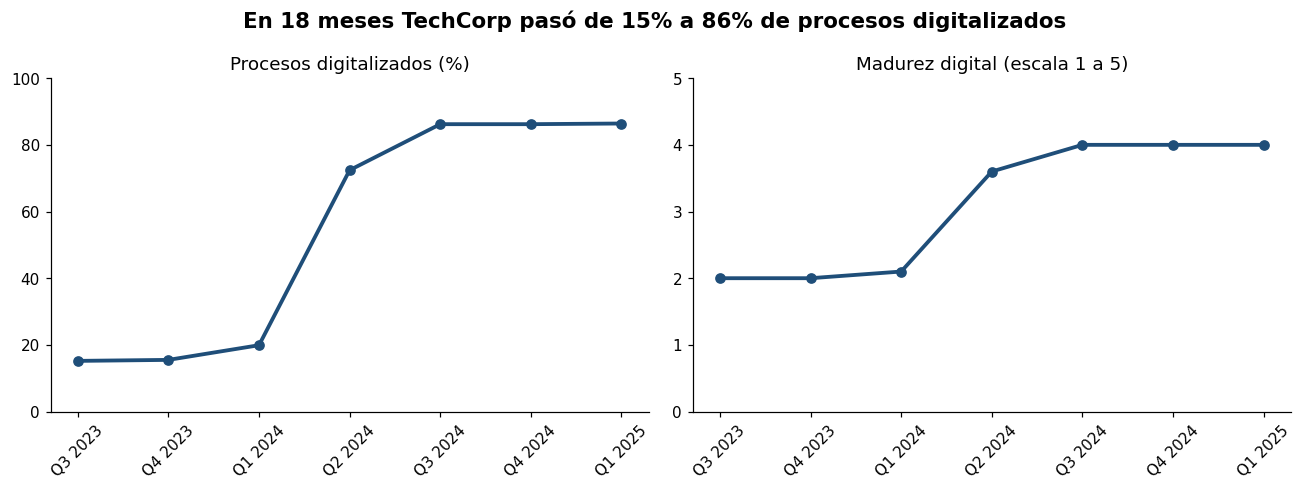

In [6]:
AZUL = "#1F4E79"
GRIS = "#B0B0B0"
ROJO = "#C0392B"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(resumen.index, resumen["procesos_digitalizados_porcentaje"],
         marker="o", color=AZUL, linewidth=2.5)
ax1.set_title("Procesos digitalizados (%)")
ax1.set_ylim(0, 100)
ax1.tick_params(axis="x", rotation=45)

ax2.plot(resumen.index, resumen["madurez_digital_score"],
         marker="o", color=AZUL, linewidth=2.5)
ax2.set_title("Madurez digital (escala 1 a 5)")
ax2.set_ylim(0, 5)
ax2.tick_params(axis="x", rotation=45)

fig.suptitle("En 18 meses TechCorp pasó de 15% a 86% de procesos digitalizados",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("01-avance-digital.png", dpi=150, bbox_inches="tight")
plt.show()

**Fuente:** columnas `procesos_digitalizados_porcentaje` y `madurez_digital_score`. **Hallazgo:** la digitalización avanzó con fuerza hasta Q3 2024 y luego se detuvo.

Usé dos paneles en vez de uno porque las escalas son distintas (porcentaje y puntaje de 1 a 5). Mezclarlas en un mismo eje distorsionaría la lectura.

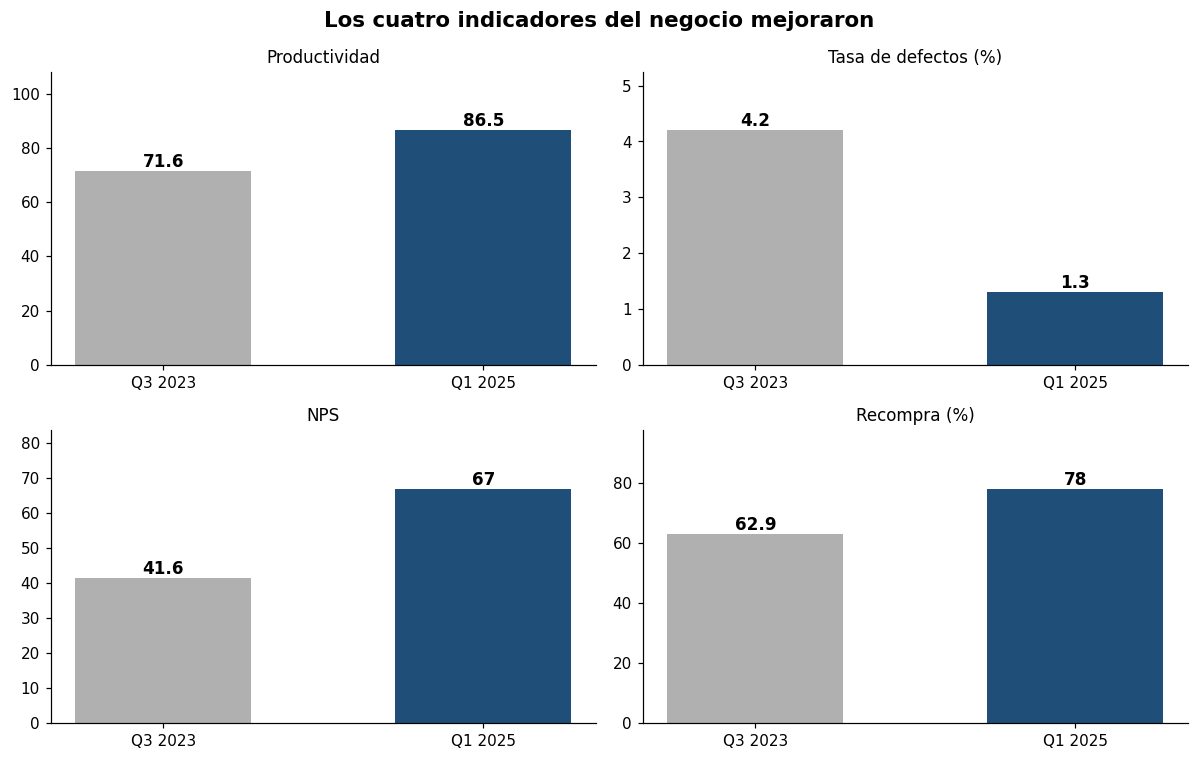

In [7]:
inicio = resumen.iloc[0]
final = resumen.iloc[-1]

metricas = [("productividad_manufactura", "Productividad"),
            ("tasa_defectos_porcentaje", "Tasa de defectos (%)"),
            ("nps_score", "NPS"),
            ("recompra_porcentaje", "Recompra (%)")]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, (col, titulo) in zip(axes.flat, metricas):
    barras = ax.bar(["Q3 2023", "Q1 2025"], [inicio[col], final[col]],
                    color=[GRIS, AZUL], width=0.55)
    ax.bar_label(barras, fontsize=11, fontweight="bold")
    ax.set_title(titulo, fontsize=11)
    ax.set_ylim(0, max(inicio[col], final[col]) * 1.25)

fig.suptitle("Los cuatro indicadores del negocio mejoraron",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("02-kpis-antes-despues.png", dpi=150, bbox_inches="tight")
plt.show()

**Fuente:** primer y último trimestre del resumen. **Hallazgo:** productividad +21%, defectos de 4,2% a 1,3%, NPS de 42 a 67 y recompra de 63% a 78%.

Repetí el mismo diseño en los cuatro paneles (principio de similitud): al ser todos iguales, se leen como un solo bloque de resultados.

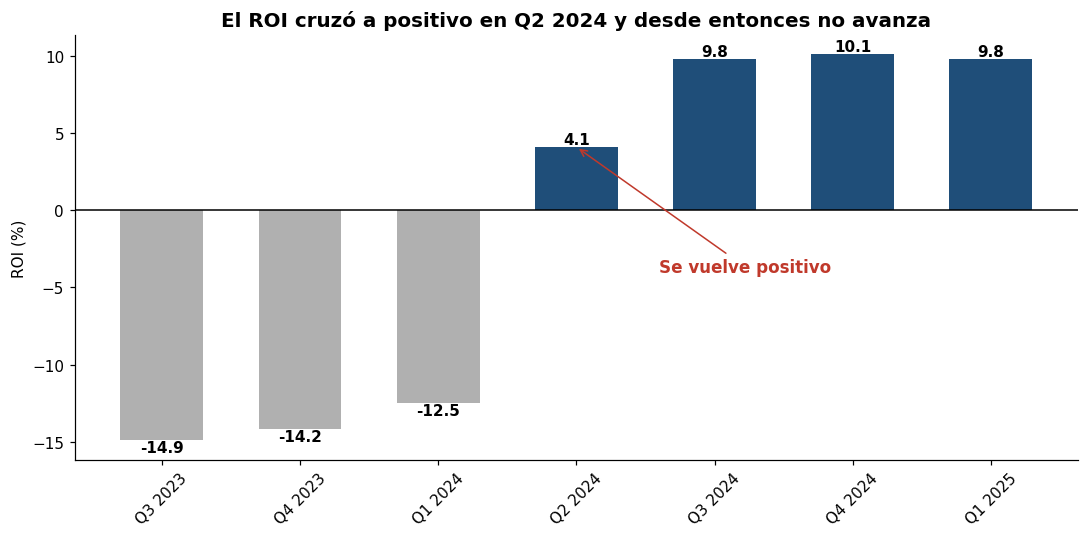

In [8]:
roi = resumen["roi_transformacion_porcentaje"]

# Gris para los trimestres en pérdida, azul para los positivos.
colores = []
for valor in roi:
    if valor < 0:
        colores.append(GRIS)
    else:
        colores.append(AZUL)

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(resumen.index, roi, color=colores, width=0.6)
ax.bar_label(barras, fontsize=10, fontweight="bold")
ax.axhline(0, color="black", linewidth=1)
ax.annotate("Se vuelve positivo", xy=(3, 4.1), xytext=(3.6, -4),
            fontsize=11, fontweight="bold", color=ROJO,
            arrowprops=dict(arrowstyle="->", color=ROJO))
ax.set_ylabel("ROI (%)")
ax.tick_params(axis="x", rotation=45)
ax.set_title("El ROI cruzó a positivo en Q2 2024 y desde entonces no avanza",
             fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("03-roi-trimestral.png", dpi=150, bbox_inches="tight")
plt.show()

**Fuente:** `roi_transformacion_porcentaje`. **Hallazgo:** la inversión dejó de ser pérdida en Q2 2024, pero lleva cuatro trimestres estancada cerca del 10%.

Separé por color los trimestres negativos de los positivos (figura-fondo) y agregué una anotación en el punto de cruce para dirigir la mirada.

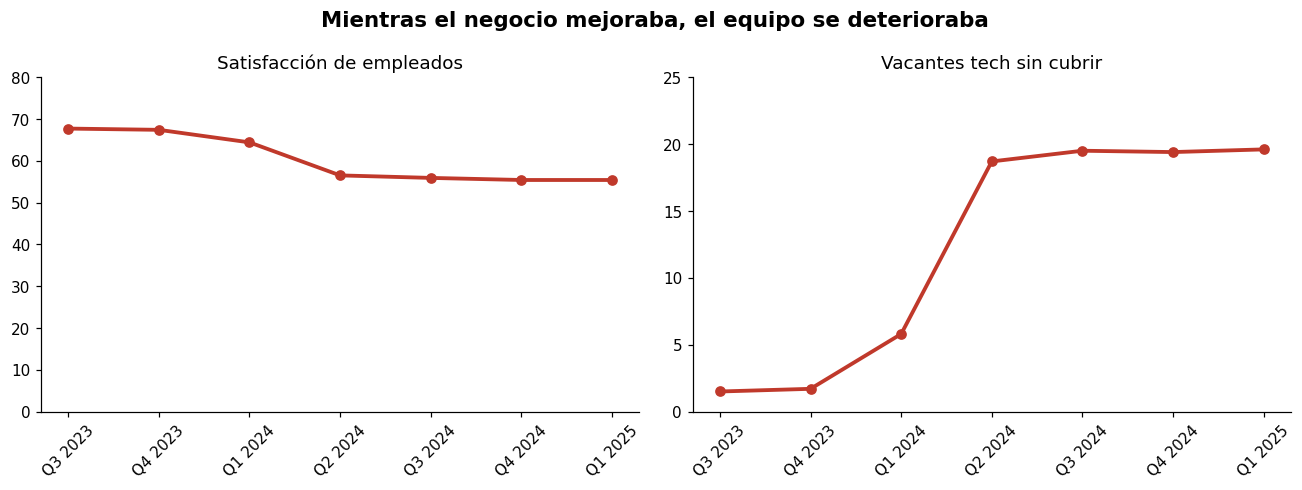

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(resumen.index, resumen["satisfaccion_empleados_score"],
         marker="o", color=ROJO, linewidth=2.5)
ax1.set_title("Satisfacción de empleados")
ax1.set_ylim(0, 80)
ax1.tick_params(axis="x", rotation=45)

ax2.plot(resumen.index, resumen["vacantes_tech_sin_cubrir"],
         marker="o", color=ROJO, linewidth=2.5)
ax2.set_title("Vacantes tech sin cubrir")
ax2.set_ylim(0, 25)
ax2.tick_params(axis="x", rotation=45)

fig.suptitle("Mientras el negocio mejoraba, el equipo se deterioraba",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("04-costo-interno.png", dpi=150, bbox_inches="tight")
plt.show()

**Fuente:** `satisfaccion_empleados_score` y `vacantes_tech_sin_cubrir`. **Hallazgo:** la satisfacción bajó 12 puntos y las vacantes sin cubrir pasaron de 1,5 a 19,6 en el mismo período.

Ambas curvas cambian en el mismo trimestre que los indicadores de negocio. Los datos muestran que ocurre al mismo tiempo, no que una cosa cause la otra.

Usé rojo en este gráfico para separarlo visualmente de los tres anteriores, que están en azul.